In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## win-rate

**Figure 3: Human preference evaluation, comparing LIMA to 5 different baselines across 300 test prompts.** LIMA's responses are preferred over Alpaca 65B (53% vs. 26%) and DaVinci003 (44% vs. 35%), and against BARD, Claude and GPT-4 they are equal or better in 58%, 46% and 43% of cases.

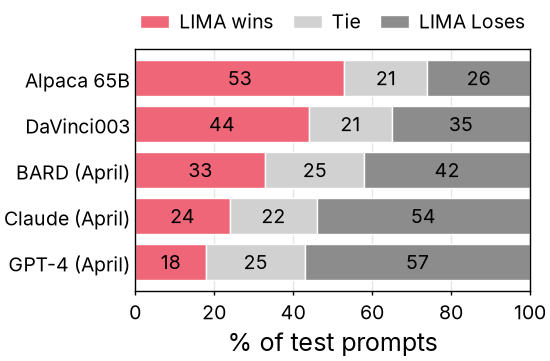

In [2]:
with open("../data/win-rate.json") as f:
    data = json.load(f)

opponents = data["opponents"]
category_colors = {
    "LIMA wins": colors["ours"],
    "Tie": lighten(colors["neutral"]),
    "LIMA Loses": colors["neutral"],
}

fig, ax = plt.subplots(figsize=(2.75, 2))
left = np.zeros(len(opponents))
for category in data["categories"]:
    shares = np.array(data[category])
    bars = ax.barh(opponents, shares, left=left, color=category_colors[category],
                   edgecolor="white", linewidth=0.5, label=category)
    ax.bar_label(bars, label_type="center", color=text_color(category_colors[category]))
    left += shares

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% of test prompts")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=3, frameon=False)

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/win-rate.pdf")
fig.savefig("../outputs/win-rate.png")
plt.show()